In [11]:
import pandas as pd

url = "../data/raw/adult24.csv"
df = pd.read_csv(url, na_values=["", " ", "-", "..", ":", "ukjent", "unknown"])
df = df[(df["SCHCURENR_A"] == 1) & (df["AGEP_A"].between(18, 29))]
df_endre = df[['ANXFREQ_A', 'DEPFREQ_A', 'K6SPD_A', 'PCNTKIDS_A', 'EDUCP_A' ]] 
df_endre.isna().sum()


ANXFREQ_A     0
DEPFREQ_A     0
K6SPD_A       0
PCNTKIDS_A    0
EDUCP_A       0
dtype: int64

Laster inn subsettet av dataframen med studenter og går over noen av kolonnnene som kommer til å bli brukt for å rense dem

In [12]:
df_endre.head()

,ANXFREQ_A,DEPFREQ_A,K6SPD_A,PCNTKIDS_A,EDUCP_A
27,5,5,2,1,5
54,1,3,2,0,8
57,5,5,2,3,1
67,1,1,2,3,5
101,1,4,2,0,4


In [13]:
df_endre.info()

<class 'pandas.DataFrame'>
Index: 1085 entries, 27 to 32628
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   ANXFREQ_A   1085 non-null   int64
 1   DEPFREQ_A   1085 non-null   int64
 2   K6SPD_A     1085 non-null   int64
 3   PCNTKIDS_A  1085 non-null   int64
 4   EDUCP_A     1085 non-null   int64
dtypes: int64(5)
memory usage: 50.9 KB


In [14]:
df_endre.nunique()

ANXFREQ_A      6
DEPFREQ_A      6
K6SPD_A        3
PCNTKIDS_A     4
EDUCP_A       10
dtype: int64

In [15]:
df_endre['ANXFREQ_A'].value_counts()

ANXFREQ_A
2    286
4    250
1    214
5    177
3    157
9      1
Name: count, dtype: int64

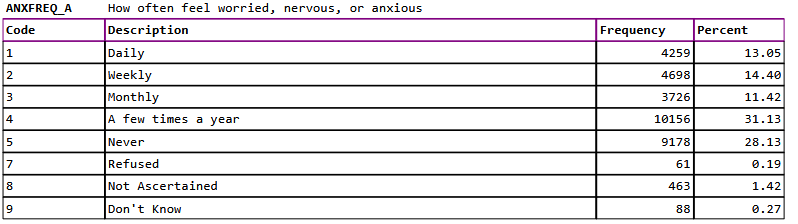

In [16]:
from IPython.display import Image
Image(filename='figures/ANXFREQ_A_explained.png') 

In [17]:
df_endre['DEPFREQ_A'].value_counts()

DEPFREQ_A
5    501
4    287
3    164
2     90
1     42
7      1
Name: count, dtype: int64

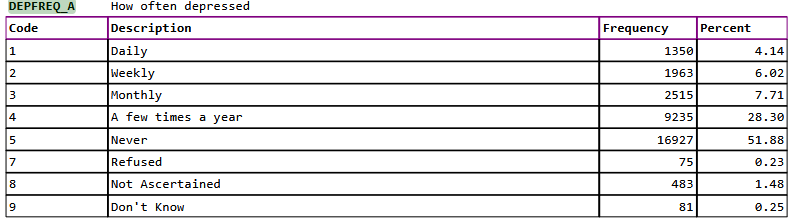

In [18]:
Image(filename='figures/DEPFREQ_A_explained.png') 

In [19]:
df_endre[ 'K6SPD_A'].value_counts()

K6SPD_A
2    1020
1      61
8       4
Name: count, dtype: int64

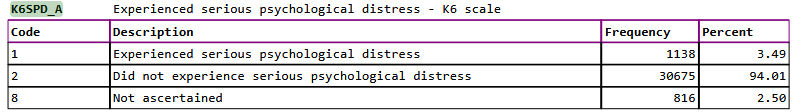

In [20]:
Image(filename='figures/K6SPD_A_explained.png') 

In [21]:
df_endre['PCNTKIDS_A'].value_counts()

PCNTKIDS_A
0    754
1    201
2     94
3     36
Name: count, dtype: int64

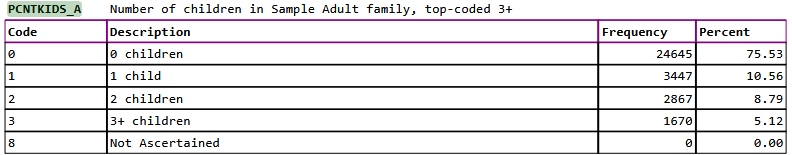

In [22]:
Image(filename='figures/PCNTKIDS_A_explained.png') 

In [23]:
df_endre['EDUCP_A'].value_counts()

EDUCP_A
5     436
8     213
4     170
7      95
1      50
9      48
2      38
6      18
3      15
10      2
Name: count, dtype: int64

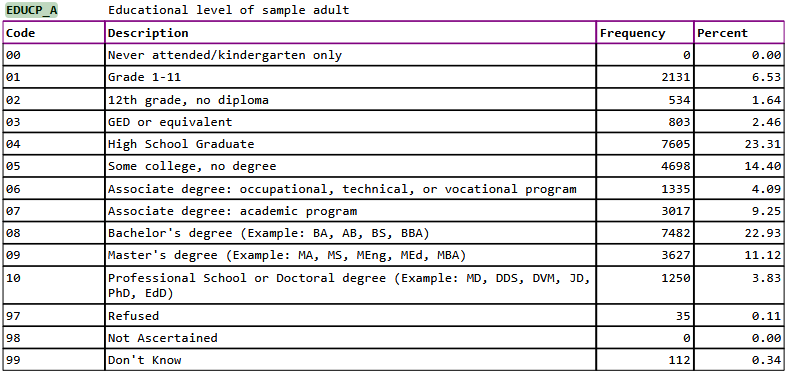

In [24]:
Image(filename='figures/EDUCP_A_explained.png') 

Gruppere etter hvilken verdier som er ukjente får å se om det er noen rekker som er verdt å fjerne

In [25]:
import numpy as np
seven_nine = ['ANXFREQ_A','DEPFREQ_A','K6SPD_A','PCNTKIDS_A']
ninty_seven_nine = ['EDUCP_A']
df_endre[seven_nine] = df_endre[seven_nine].replace({7: np.nan, 8: np.nan, 9: np.nan})
df_endre[ninty_seven_nine] = df_endre[ninty_seven_nine].replace({97: np.nan, 98: np.nan, 99: np.nan})
df_endre['ANXFREQ_A'].value_counts(dropna=False)
df_endre = df_endre.reset_index(drop=True)

In [26]:
df_endre_null = df_endre[df_endre.isna().any(axis=1)]
print(df_endre_null)

      ANXFREQ_A  DEPFREQ_A  K6SPD_A  PCNTKIDS_A  EDUCP_A
43          NaN        4.0      2.0           0        8
185         3.0        4.0      NaN           0        4
459         4.0        5.0      NaN           0        8
625         2.0        NaN      NaN           1        5
1024        1.0        4.0      NaN           0        2


In [27]:
#added possible grouping
def EDU_LVL(value):
    if pd.isna(value):
        return None
    if value < 4.0:
        return 0.0
    elif 4.0 <= value < 10.0:
        return 1.0
    else:
        return 2.0

df_endre['EDU_LVL'] = df_endre['EDUCP_A'].map(EDU_LVL)
print(df_endre)


      ANXFREQ_A  DEPFREQ_A  K6SPD_A  PCNTKIDS_A  EDUCP_A  EDU_LVL
0           5.0        5.0      2.0           1        5      1.0
1           1.0        3.0      2.0           0        8      1.0
2           5.0        5.0      2.0           3        1      0.0
3           1.0        1.0      2.0           3        5      1.0
4           1.0        4.0      2.0           0        4      1.0
...         ...        ...      ...         ...      ...      ...
1080        1.0        3.0      2.0           0        5      1.0
1081        4.0        5.0      2.0           0        5      1.0
1082        4.0        5.0      2.0           0        5      1.0
1083        4.0        5.0      2.0           0        7      1.0
1084        2.0        5.0      2.0           2        1      0.0

[1085 rows x 6 columns]


In [28]:
df_endre = df_endre.rename(columns={
    "ANXFREQ_A": "anxiety_frequency",
    "DEPFREQ_A": "depression_frequency",
    "K6SPD_A": "serious_distress",
    "PCNTKIDS_A": "kids_household",
    "EDUCP_A": "education_level",
    "edu_lvl": "education_level_grp"
})
print(df_endre)

      anxiety_frequency  depression_frequency  serious_distress  \
0                   5.0                   5.0               2.0   
1                   1.0                   3.0               2.0   
2                   5.0                   5.0               2.0   
3                   1.0                   1.0               2.0   
4                   1.0                   4.0               2.0   
...                 ...                   ...               ...   
1080                1.0                   3.0               2.0   
1081                4.0                   5.0               2.0   
1082                4.0                   5.0               2.0   
1083                4.0                   5.0               2.0   
1084                2.0                   5.0               2.0   

      kids_household  education_level  EDU_LVL  
0                  1                5      1.0  
1                  0                8      1.0  
2                  3                1      0.0  

In [29]:
df_endre.to_csv("../data/processed/endre_clean.csv", index=False)